# Explore the expense data with one line on the purpose.

## 1. Imports, Data, and Plot Style


In [1]:
# 1. Imports, data, and plot style
import matplotlib.pyplot as plt
from matplotlib.ticker import StrMethodFormatter, PercentFormatter
import pandas as pd
import seaborn as sns
from statsmodels.stats.proportion import proportion_confint
from scipy.stats import chi2_contingency, mannwhitneyu
import yaml

from expense_agent.data import load_claims, load_dataset
from expense_agent.paths import GENERATED_DIR, POLICY_PATH
from expense_agent.policy import cap_usage, load_policy

DATE_COLS = ["expense_date", "submitted_date"]
POLICY = load_policy(POLICY_PATH)

claims = load_claims(GENERATED_DIR) # what the agent sees: no labels
labeled = load_dataset(GENERATED_DIR) # with answer key: section 5 only
for frame in (claims, labeled):
    frame[DATE_COLS] = frame[DATE_COLS].apply(pd.to_datetime)
history = pd.read_csv(
    GENERATED_DIR / "spend_history.csv", parse_dates=["week_start"]
)

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (9, 4.5)
plt.rcParams["text.parse_math"] = False # "$ in titles means dollars"
assert len(claims) == len(labeled), "Label join lost rows"
assert "violation_type" not in claims.columns, "Labels leaked into claims"
print(
    f"claims: {claims.shape} | labeled: {labeled.shape} | "
    f"history: {history.shape}"
)


claims: (330, 26) | labeled: (330, 32) | history: (780, 3)


## 2; Data Profile (data dictionary)

In [2]:
# 2 Data profile: one row per column
REQUIRED = [
    "claim_id",
    "report_id",
    "employee_id",
    "department",
    "expense_date",
    "submitted_date",
    "category",
    "amount",
    "receipt_attached",
]

def profile(df: pd.DataFrame) -> pd.DataFrame:
    """Summarize each column: dtype, % missing, distinct values, example."""
    return pd.DataFrame(
        {
            "dtype": df.dtypes.astype(str),
            "missing_pct": df.isna().mean().mul(100).round(1),
            "n_unique": df.nunique(),
            "example": df.bfill().iloc[0],
        }
    )
claims_profile = profile(claims)

assert claims["claim_id"].is_unique, "claim_id must be unique"
assert claims_profile.loc[REQUIRED, "missing_pct"].eq(0).all(), (
    "A required field has missing values"
)
assert (claims["amount"] > 0).all(), "Non-positive amount"
assert (claims["submitted_date"] >= claims["expense_date"]).all(),  (
    "Submitted before the expense happened"
)

print(f"{claims.shape[1]} columns; required fields complete")
claims_profile.sort_values("missing_pct", ascending=False)


26 columns; required fields complete


,dtype,missing_pct,n_unique,example
rental_class,str,99.1,2,Compact
miles,Int64,97.9,7,92
attendee_names,str,90.3,32,Alex Morgan (Soylent Foods); employee
attendees,Int64,90.3,4,2
nights,Int64,82.1,3,1
flight_hours,float64,81.5,27,2.2
fare_class,str,81.5,2,Economy
report_id,str,0.0,100,R-E001-01
employee_id,str,0.0,10,E001
preapproved,bool,0.0,2,False


## 3 Summary statistics

In [3]:
# 3 Summary statistics: spend by category, department and employee
def p90(values:pd.Series) -> float:
    """Return the 90th percentile( a function reads well as a column)."""
    return values.quantile(0.9)

def spend_summary(df: pd.DataFrame, by: str | list[str]) -> pd.DataFrame:
    """Count, total, mean, median, and p90 of amount per group, largest first."""
    summary = (
        df.groupby(by)["amount"].agg(
            claims="count",
            total="sum",
            mean="mean",
            median="median",
            p90=p90,
        )
    ).sort_values("total", ascending=False)
    summary["share_pct"] = summary["total"] / summary["total"].sum() * 100
    return summary.round(2)

by_category = spend_summary(claims, "category")
by_department = spend_summary(claims, "department")
by_employee = spend_summary(claims, ["department", "employee_name"])

headcount = claims.groupby("department")["employee_id"].nunique()
by_department["employees"] = headcount
by_department["per_employee"] = (by_department["total"] / headcount).round(2)

# --- checks: every view must add back up to the same total ---
grand_total = claims["amount"].sum()
for name, table in [
    ("category", by_category),
    ("department", by_department),
    ("employee", by_employee),
]:
    assert abs(table["total"].sum() - grand_total) < 0.01, f"{name} total"
    assert table["claims"].sum() == len(claims), f"{name} count"
    assert (table["median"] <= table["p90"]).all(), f"{name} median > p90"
assert headcount.sum() == claims["employee_id"].nunique(), "Headcount"

amount = claims["amount"]
print(
    f"Total ${grand_total:,.2f} | mean ${amount.mean():,.2f} | "
    f"median ${amount.median():,.2f} | skew {amount.skew():,.2f}"
)
display(by_category)
display(by_department)
by_employee.head(5)

Total $117,376.99 | mean $355.69 | median $220.89 | skew 4.43


,claims,total,mean,median,p90,share_pct
category,,,,,,
Airfare,61,41094.51,673.68,422.23,633.15,35.01
Lodging,62,25908.52,417.88,400.45,629.92,22.07
Conference,15,22523.77,1501.58,1156.80,2688.27,19.19
Client Meals,32,8537.78,266.81,248.79,382.49,7.27
Home Office,25,7153.17,286.13,220.31,393.03,6.09
Software,34,5046.50,148.43,165.97,266.81,4.30
Meals,48,2490.55,51.89,44.08,82.70,2.12
Ground Transport,24,2362.58,98.44,63.54,281.26,2.01
Office Supplies,22,1676.86,76.22,70.65,111.45,1.43


,claims,total,mean,median,p90,share_pct,employees,per_employee
department,,,,,,,,
Sales,120,46785.80,389.88,247.34,580.65,39.86,3,15595.27
Engineering,85,28906.83,340.08,217.46,625.62,24.63,3,9635.61
Marketing,67,23520.22,351.05,244.46,697.46,20.04,2,11760.11
Operations,29,13421.69,462.82,259.34,609.66,11.43,1,13421.69
Finance,29,4742.45,163.53,115.52,260.93,4.04,1,4742.45


claims     total    mean  median     p90  \
department  employee_name                                              
Sales       Sofia Nguyen        39  17442.96  447.26  274.18  590.95   
Engineering Lena Brooks         32  15037.27  469.91  266.69  722.24   
Sales       Dana Whitfield      40  14966.12  374.15  243.46  546.15   
            Jamal Carter        41  14376.72  350.65  241.11  574.48   
Operations  Tom Becker          29  13421.69  462.82  259.34  609.66   

                            share_pct  
department  employee_name              
Sales       Sofia Nguyen        14.86  
Engineering Lena Brooks         12.81  
Sales       Dana Whitfield      12.75  
            Jamal Carter        12.25  
Operations  Tom Becker          11.43

## 4. Distributions

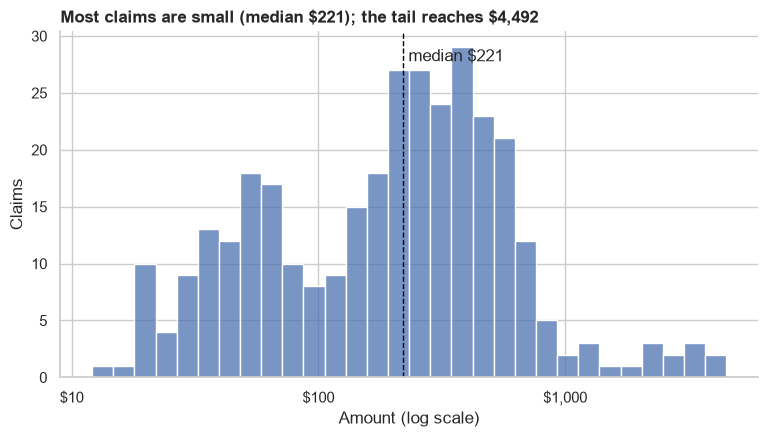

In [4]:
# 4a Style helper + distribution of claim amount (log scale)
DOLLARS = StrMethodFormatter("${x:,.0f}")

def style_axes(
        ax: plt.Axes, title: str, xlabel: str, ylabel: str = ""
) -> None:
    """Apply the notebook chart style: takeaway title, label, no clutter. """
    ax.set_title(title, loc="left", fontsize=12, fontweight="bold")
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    sns.despine(ax=ax)

median_amount = claims["amount"].median()
max_amount = claims["amount"].max()

fig, ax = plt.subplots()
sns.histplot(claims, x="amount", bins=30, log_scale=True, ax=ax)
ax.axvline(median_amount, color="black", linestyle="--", linewidth=1)
ax.text(
    median_amount,
    ax.get_ylim()[1] * 0.95,
    f" median ${median_amount:,.0f}",
    va="top",
)
ax.xaxis.set_major_formatter(DOLLARS)
style_axes(
    ax,
    f"Most claims are small (median ${median_amount:,.0f}); "
    f"the tail reaches ${max_amount:,.0f}",
    "Amount (log scale)",
    "Claims",
)
plt.show()

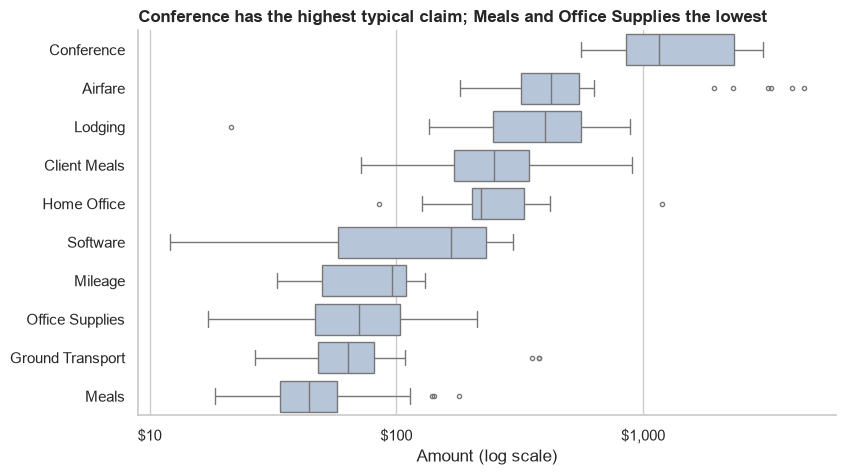

In [5]:
# 4b Amount by category, ordered by median
category_order = (
    claims.groupby("category")["amount"]
    .median()
    .sort_values(ascending=False)
    .index
)
top_category = category_order[0]

fig, ax = plt.subplots(figsize=(9, 5))
sns.boxplot(
    claims,
    x="amount",
    y="category",
    order=category_order,
    log_scale=True,
    color="lightsteelblue",
    fliersize=3,
    ax=ax,
    )
ax.xaxis.set_major_formatter(DOLLARS)
style_axes(
    ax,
    f"{top_category} has the highest typical claim; "
    "Meals and Office Supplies the lowest",
    "Amount (log scale)",
)
plt.show()

Skipped 3 Lodging incidentals (no nights)


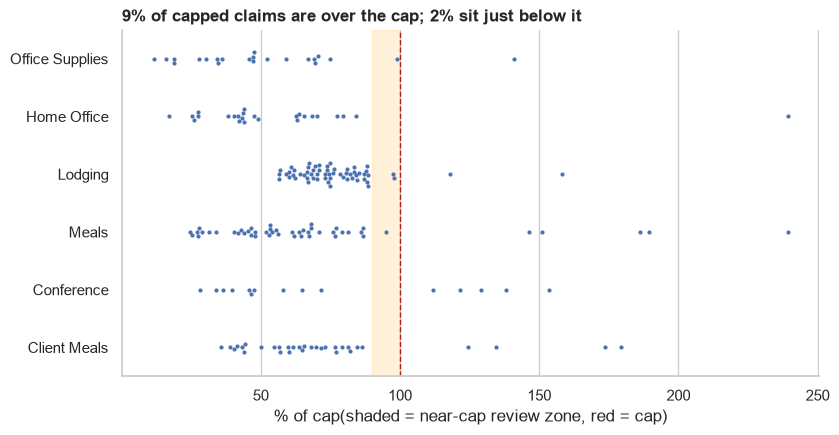

zone,under 90%,near cap (90-100%),over cap,All
category,,,,
Client Meals,28,0,4,32
Conference,10,0,5,15
Home Office,24,0,1,25
Lodging,55,2,2,59
Meals,42,1,5,48
Office Supplies,20,1,1,22
All,179,4,18,201


In [6]:
# 4c Amount as % of its cap for capped categories
NEAR_CAP_START = (1 - POLICY["escalation"]["near_cap_pct"]) * 100
ZONE_LABELS = ["under 90%", "near cap (90-100%)", "over cap"]

def cap_pct(claim: dict) -> float | None:
    """Return the claim's value as a % of its cap, or None if uncapped."""
    usage = cap_usage(claim, POLICY)
    return None if usage is None else usage[0] / usage[1] * 100
capped = claims.assign(
cap_pct=[cap_pct(c) for c in claims.to_dict("records")]
).dropna(subset=["cap_pct"])
capped["zone"] = pd.cut(
    capped["cap_pct"],
    bins=[0, NEAR_CAP_START, 100, float("inf")],
    labels=ZONE_LABELS,
    right=False,
)
zone_share = capped["zone"].value_counts(normalize=True)

# --- checks ---
capped_categories ={
    "Lodging",
    "Meals",
    "Client Meals",
    "Conference",
    "Home Office",
    "Office Supplies",
}
client_meals = claims[claims["category"] == "Client Meals"]
missing_attendees = client_meals["attendees"].isna() | client_meals["attendees"].le(0)
no_cap_basis = claims["category"].eq("Lodging") & claims["nights"].isna()
has_cap = claims["category"].isin(capped_categories) & ~no_cap_basis
assert len(capped) == has_cap.sum(), "Capped claim count"
assert capped["cap_pct"].gt(0).all(), "Non-positive cap usage"
assert capped["zone"].notna().all(), "A claim fell outside every zone"
assert not missing_attendees.any(), (f"{missing_attendees.sum()} Client Meals lack attendees")
print(f"Skipped {no_cap_basis.sum()} Lodging incidentals (no nights)")
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.axvspan(NEAR_CAP_START, 100, color="orange", alpha=0.15)
ax.axvline(100, color="firebrick", linestyle="--", linewidth=1)
sns.swarmplot(capped, x="cap_pct", y="category", size=3, ax=ax)
style_axes(
    ax,
    f"{zone_share['over cap']:.0%} of capped claims are over the cap; "
    f"{zone_share['near cap (90-100%)']:.0%} sit just below it",
    "% of cap(shaded = near-cap review zone, red = cap)",
)
plt.show()
pd.crosstab(capped["category"], capped["zone"], margins=True)


## 5 Monthly spend and day-of-week mix

Expense dates 2026-02-21 -> 2026-10-17


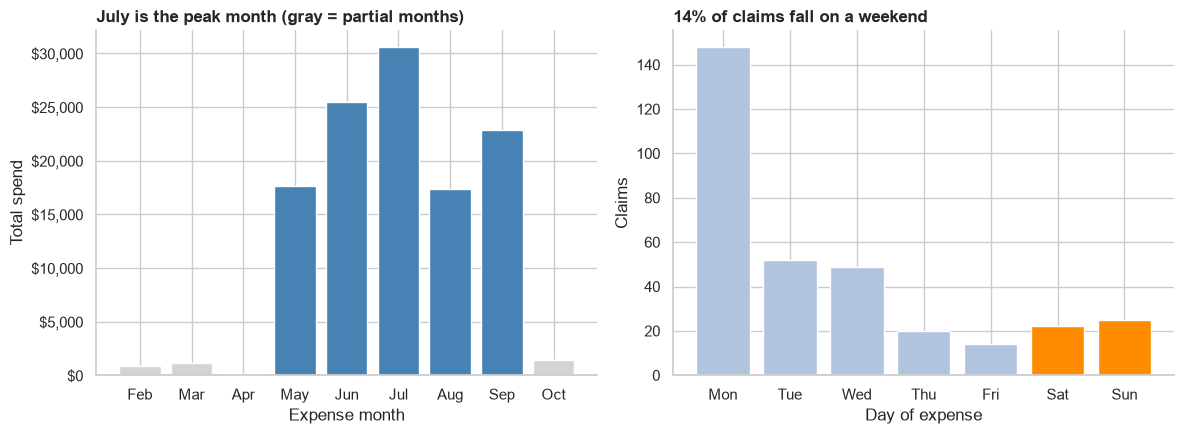

,claims,total
expense_date,,
2026-02-01,2,824.55
2026-03-01,3,1145.35
2026-04-01,2,110.68
2026-05-01,54,17649.33
2026-06-01,63,25449.33
2026-07-01,78,30600.04
2026-08-01,66,17313.20
2026-09-01,53,22829.06
2026-10-01,9,1455.45


In [7]:
#5a Time patterns: monthly spend and day-of-week mix
DAY_ORDER = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
FULL_MONTH_MIN_CLAIMS = 20 # below this, the month is a window edge
monthly = (
    claims.set_index("expense_date")
    .resample("MS")["amount"]
    .agg(claims="count", total="sum")
)
weekday = (claims["expense_date"]
           .dt.day_name()
           .str[:3].value_counts()
           .reindex(DAY_ORDER, fill_value=0)
)
weekend_share = weekday[["Sat", "Sun"]].sum() / weekday.sum()
peak_month = monthly["total"].idxmax()



partial = monthly["claims"] < FULL_MONTH_MIN_CLAIMS

# --- checks ---
assert abs(monthly["total"].sum() - claims["amount"].sum()) < 0.01, "Total"
assert monthly["claims"].sum() == len(claims), "Monthly count"
assert weekday.sum() == len(claims), "Weekday count"
print(
    f"Expense dates {claims['expense_date'].min():%Y-%m-%d} -> "
    f"{claims['expense_date'].max():%Y-%m-%d}"
)

fig, (ax_month, ax_day) = plt.subplots(1, 2, figsize=(12, 4.5))
ax_month.bar(
    monthly.index.strftime("%b"),
    monthly["total"],
    color=["lightgray" if p else "steelblue" for p in partial], 
)
ax_month.yaxis.set_major_formatter(DOLLARS)
style_axes(
    ax_month,
    f"{peak_month:%B} is the peak month (gray = partial months)",
    "Expense month",
    "Total spend",
)
colors = ["lightsteelblue"] * 5 + ["darkorange"] * 2
ax_day.bar(weekday.index, weekday.values, color=colors)
style_axes(
    ax_day,
    f"{weekend_share:.0%} of claims fall on a weekend", 
    "Day of expense",
      "Claims"
)
fig.tight_layout()
plt.show()
monthly

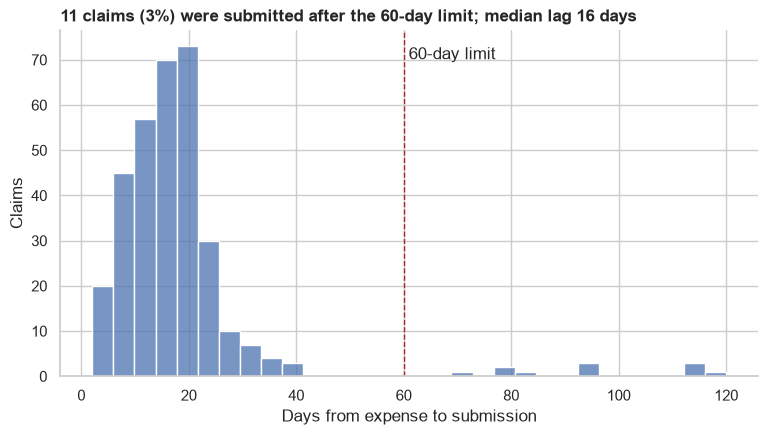

count    330.0
mean      18.5
std       16.3
min        2.0
25%       11.0
50%       16.0
75%       20.0
max      120.0
dtype: float64

In [8]:
# 5b Submission lag vs the 60-day limit(POL-1.2)
MAX_DAYS = POLICY["submission"]["max_days_after_expense"]

lag_days = (claims["submitted_date"] - claims["expense_date"]).dt.days
late = lag_days > MAX_DAYS


# --- checks ---
assert lag_days.ge(0).all(), "Negative lag"
assert lag_days.notna().all(), "Missing lag"

fig, ax = plt.subplots()
sns.histplot(lag_days, bins=30, ax=ax)
ax.axvline(MAX_DAYS, color="firebrick", linestyle="--", linewidth=1)
ax.text(MAX_DAYS, ax.get_ylim()[1] * 0.95, f" {MAX_DAYS}-day limit", va="top")
style_axes(
    ax,
    f"{late.sum()} claims ({late.mean():.0%}) were submitted after the "
    f"{MAX_DAYS}-day limit; median lag {lag_days.median():.0f} days",
    "Days from expense to submission",
    "Claims",
)
plt.show()
lag_days.describe().round(1)

## 6. Label-aware view ( understanding only: never tunes 03 or 04 )

82 of 330 claims out of policy(24.8%)


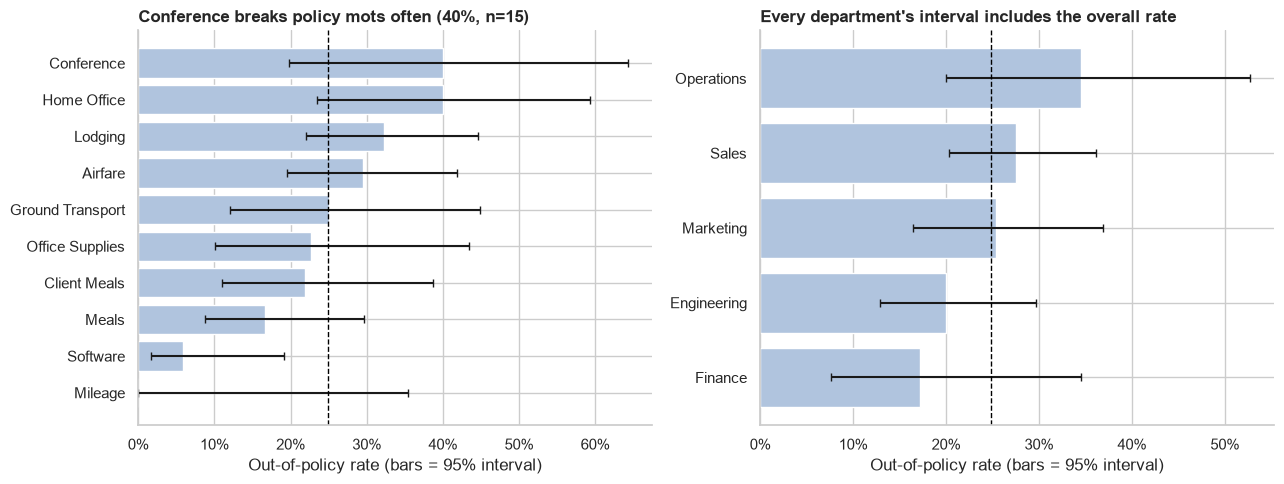

,claims,violations,rate,ci_low,ci_high
category,,,,,
Conference,15,6,0.400,0.198,0.643
Home Office,25,10,0.400,0.234,0.593
Lodging,62,20,0.323,0.220,0.446
Airfare,61,18,0.295,0.196,0.419
Ground Transport,24,6,0.250,0.120,0.449
Office Supplies,22,5,0.227,0.101,0.434
Client Meals,32,7,0.219,0.110,0.388
Meals,48,8,0.167,0.087,0.296
Software,34,2,0.059,0.016,0.191


,claims,violations,rate,ci_low,ci_high
department,,,,,
Operations,29,10,0.345,0.199,0.527
Sales,120,33,0.275,0.203,0.361
Marketing,67,17,0.254,0.165,0.369
Engineering,85,17,0.200,0.129,0.297
Finance,29,5,0.172,0.076,0.345


In [9]:
# 6a Violation rate by category and department (labels: understanding only)
outcomes = labeled.assign(out_of_policy=~labeled["in_policy"])
overall_rate = outcomes["out_of_policy"].mean()


def violation_rates(df:pd.DataFrame, by: str) -> pd.DataFrame:
    """Return violations, rate and 95% Wilson interval per group.
    
    Bounds are clipped to the rate: at 0% or 100% floating-point
    rounding can leave the bound a hair (~1e-17) on the wrong side.
    """
    rates = df.groupby(by)["out_of_policy"].agg(claims="count", violations="sum")
    rates["rate"] = rates["violations"] / rates["claims"]
    low, high = proportion_confint(rates["violations"], rates["claims"], alpha=0.05, method="wilson")
    rates["ci_low"] = low
    rates["ci_high"] = high
    rates["ci_low"] = rates["ci_low"].clip(upper=rates["rate"])
    rates["ci_high"] = rates["ci_high"].clip(lower=rates["rate"])
    return rates.sort_values("rate", ascending=False)
    


def plot_rates(ax: plt.Axes, rates: pd.DataFrame, title: str) -> None:
    """Draw horizontal rate bars with 95% intervals and the overall line."""
    errors = [
        rates["rate"] - rates["ci_low"],
        rates["ci_high"] - rates["rate"],
    ]
    ax.barh(
        rates.index,
        rates["rate"],
        xerr=errors,
        color="lightsteelblue",
        capsize=3,
    )
    ax.axvline(overall_rate, color="black", linestyle="--", linewidth=1)
    ax.invert_yaxis()
    ax.xaxis.set_major_formatter(PercentFormatter(xmax=1))
    style_axes(ax, title, "Out-of-policy rate (bars = 95% interval)")

by_cat_rate = violation_rates(outcomes, "category")
by_dept_rate = violation_rates(outcomes, "department")

# --- checks ---
n_violations = outcomes["out_of_policy"].sum()
assert labeled["in_policy"].dtype == bool, "in_policy must load as bool"
for name, table in [("category", by_cat_rate), ("department", by_dept_rate)]:
    assert table["violations"].sum() == n_violations, f"{name} violations"
    assert table["claims"].sum() == len(outcomes), f"{name} claims"
    inside = table["ci_low"].le(table["rate"]) & table["rate"].le(table["ci_high"])
    assert inside.all(), f"{name} rate outside its interval"
print(
    f"{n_violations} of {len(outcomes)} claims out of policy"
    f"({overall_rate:.1%})"
)
top_cat = by_cat_rate.index[0]
dept_covers_overall = (
    by_dept_rate["ci_low"].le(overall_rate)
    & by_dept_rate["ci_high"].ge(overall_rate)
).all()
dept_title = (
    "Every department's interval includes the overall rate"
    if dept_covers_overall
    else "At least one department differs from the overall rate"
)

fig, (ax_cat, ax_dept) = plt.subplots(1, 2, figsize=(13, 5))
plot_rates(
    ax_cat,
    by_cat_rate,
    f"{top_cat} breaks policy mots often "
    f"({by_cat_rate['rate'].iloc[0]:.0%}, n={by_cat_rate['claims'].iloc[0]})",
)
plot_rates(ax_dept, by_dept_rate, dept_title)
fig.tight_layout()
plt.show()
display(by_cat_rate.round(3))
by_dept_rate.round(3)

Late rule flags 11 claims: 11 of 11 late_submission labels, plus 0 labeled as another violation


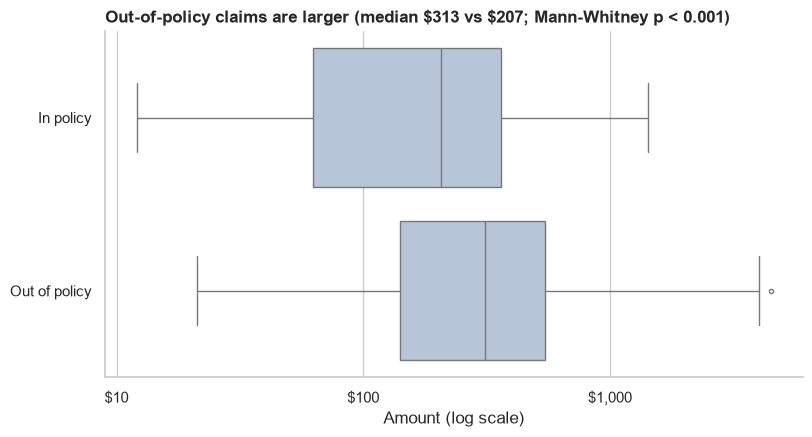

,claims,median,p90,total
out_of_policy,,,,
In policy,248,206.65,571.82,63501.26
Out of policy,82,312.70,2303.24,53875.73


label: late_submission,False,True
rule: late,,
False,319,0
True,0,11


In [11]:
# 6b Amounts in vs out of policy, and the late rule vs the labels
status = outcomes["out_of_policy"].map(
    {False: "In policy", True: "Out of policy"}
)
amount_summary = outcomes.groupby(status)["amount"].agg(claims="count", median="median", p90=p90, total="sum")
in_amounts = outcomes.loc[~outcomes["out_of_policy"], "amount"]
out_amounts = outcomes.loc[outcomes["out_of_policy"], "amount"]
amount_test = mannwhitneyu(out_amounts, in_amounts, alternative="two-sided")

rule_late = (
    outcomes["submitted_date"] - outcomes["expense_date"]
).dt.days > MAX_DAYS
label_late = outcomes["violation_type"].eq("late_submission")
late_check = pd.crosstab(rule_late.rename("rule: late"),
                         label_late.rename("label: late_submission"),
                         )

# --- checks ---
assert amount_summary["claims"].sum() == len(outcomes), "Status counts"
assert rule_late.sum() == late.sum(), "Rule disagrees with 5b"
assert not (rule_late & outcomes["in_policy"]).any(), (
    "Late rule flags an in-policy claim"
)
assert not (label_late & ~rule_late).any(), (
    "A late_submission label is not late by the rule"
)
print(
    f"Late rule flags {rule_late.sum()} claims: "
    f"{(rule_late & label_late).sum()} of {label_late.sum()} "
    f"late_submission labels, plus "
    f"{(rule_late & ~label_late).sum()} labeled as another violation"
)

out_median = amount_summary.loc["Out of policy", "median"]
in_median = amount_summary.loc["In policy", "median"]
direction = "larger" if out_median > in_median else "smaller"

p_text = (
    "p < 0.001"
    if amount_test.pvalue < 0.001
    else f"p = {amount_test.pvalue:.3f}"
)

fig, ax = plt.subplots()
sns.boxplot(
    x=outcomes["amount"],
    y=status,
    order=["In policy", "Out of policy"],
    log_scale=True,
    color="lightsteelblue",
    fliersize=3,
    ax=ax,
)
ax.xaxis.set_major_formatter(DOLLARS)
style_axes(
    ax,
    f"Out-of-policy claims are {direction} (median ${out_median:,.0f} "
    f"vs ${in_median:,.0f}; Mann-Whitney {p_text})", 
    "Amount (log scale)",
)
plt.show()
display(amount_summary.round(2))
late_check

In [13]:
# 6c Chi-square test: is the violation rate independent of department?
ALPHA = 0.05
MIN_EXPECTED = 5 # chi-square is unreliable below this expected count

dept_table = pd.crosstab(outcomes["department"], outcomes["out_of_policy"])
chi2, p_value, dof, expected_counts = chi2_contingency(dept_table)
expected = pd.DataFrame(
    expected_counts, index=dept_table.index, columns=dept_table.columns
)
n_total = dept_table.to_numpy().sum()
cramers_v = (chi2 / (n_total * (min(dept_table.shape) - 1))) ** 0.5

# Why category is not tested: some expected counts are too small
cat_table = pd.crosstab(outcomes["category"], outcomes["out_of_policy"])
cat_expected_min = chi2_contingency(cat_table)[3].min()

# --- checks ---
assert n_total == len(outcomes), "Table lost claims"
assert dof == (dept_table.shape[0] - 1) * (dept_table.shape[1] - 1), "dof"
assert expected.to_numpy().min() >= MIN_EXPECTED,  (
    "Expected count below 5: chi-square unreliable"
)

verdict = "no evidence" if p_value >= ALPHA else "evidence"
print(
    f"Department: chi2 = {chi2:.2f}, dof = {dof}, p = {p_value:.3f}, "
    f"Cramer's V = {cramers_v:.2f} -> {verdict} that the violation rate "
    f"depends on department"
)
print(
    f"Category not tested; smallest expected count {cat_expected_min:.1f} "
    f"< {MIN_EXPECTED}"
)
dept_table.assign(
    expected_violations=expected[True].round(1),
    rate=(dept_table[True] / dept_table.sum(axis=1)).round(3),
)

Department: chi2 = 3.87, dof = 4, p = 0.424, Cramer's V = 0.11 -> no evidence that the violation rate depends on department
Category not tested; smallest expected count 1.7 < 5


out_of_policy,False,True,expected_violations,rate
department,,,,
Engineering,68,17,21.1,0.200
Finance,24,5,7.2,0.172
Marketing,50,17,16.6,0.254
Operations,19,10,7.2,0.345
Sales,87,33,29.8,0.275
